# AI-Assisted Writing Detection — End-to-End ML Pipeline

**Goal:** Predict `Is_AI_Assisted` (1 = AI-assisted submission, 0 = human-written) from writing-behavior and stylometric metadata (word count, editing time, revision count, typing speed, grammar errors, etc.)

**Pipeline modules:**
1. Setup & Imports
2. Load Data
3. Exploratory Data Analysis (EDA)
4. Data Cleaning & Missing-Value Imputation
5. Feature Engineering & Encoding
6. Train / Test Split
7. Feature Scaling
8. Handling Class Imbalance
9. Model Training — Logistic Regression, SVM, XGBoost
10. Hyperparameter Tuning
11. Model Evaluation & Comparison
12. Feature Importance
13. Save the Best Model
14. Inference on New Data

> Replace `DATA_PATH` in the next section if your file is named/located differently.


## 1. Setup & Imports

In [4]:
# Core
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Imbalance handling
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)

# Persistence
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load Data

In [5]:
DATA_PATH = "ai_writing_detection_dataset.csv"   # <-- update path if needed

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (10200, 20)


,Student_ID,Submission_Type,Academic_Level,Primary_Language,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Font_Family,Submission_Hour,Is_AI_Assisted
0,16959e76,Lab_Report,Postgraduate,Native,1552,16.90,8,0.62,0.11,11.85,129.05,16.0,24.70,3.02,0.0,0.08,2.01,Arial,18,0
1,0a304e7f,Research_Paper,Undergraduate,Native,950,16.71,5,0.47,0.31,10.34,236.60,23.0,38.84,1.71,15.0,0.07,1.72,Helvetica,15,0
2,6e629f9f,Essay,Undergraduate,Non_Native,1103,22.10,1,0.76,0.38,14.35,4.72,4.0,0.00,0.41,0.0,0.08,2.35,Arial,17,1
3,16334d32,Essay,Postgraduate,Native,1189,20.00,7,0.61,0.26,10.93,NaN,24.0,41.92,3.06,5.0,0.05,1.68,Times New Roman,5,0
4,54d8e254,Essay,Undergraduate,Native,1035,22.67,2,0.80,0.33,15.30,16.82,2.0,0.00,2.78,1.0,0.09,2.90,Helvetica,8,1


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10200 entries, 0 to 10199
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Student_ID               10200 non-null  object 
 1   Submission_Type          10200 non-null  object 
 2   Academic_Level           10200 non-null  object 
 3   Primary_Language         10200 non-null  object 
 4   Word_Count               10200 non-null  int64  
 5   Average_Sentence_Length  10200 non-null  float64
 6   Grammar_Errors           10200 non-null  int64  
 7   Vocabulary_Richness      10200 non-null  float64
 8   Passive_Voice_Ratio      10200 non-null  float64
 9   Reading_Level            10200 non-null  float64
 10  Editing_Time             9311 non-null   float64
 11  Revision_Count           8687 non-null   float64
 12  Typing_Speed             9197 non-null   float64
 13  Plagiarism_Score         9387 non-null   float64
 14  Citation_Count        

In [7]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,10200,10000,f867991c,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Submission_Type,10200,4,Essay,4009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic_Level,10200,3,Undergraduate,6218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Primary_Language,10200,2,Native,7687,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Word_Count,10200.0,NaN,NaN,NaN,1201.668627,395.173748,300.0,925.0,1196.0,1471.0,2588.0
Average_Sentence_Length,10200.0,NaN,NaN,NaN,16.941588,4.6356,5.0,13.62,17.08,20.64,33.62
Grammar_Errors,10200.0,NaN,NaN,NaN,7.336275,5.049967,0.0,5.0,7.0,9.0,78.0
Vocabulary_Richness,10200.0,NaN,NaN,NaN,0.622392,0.098764,0.29,0.55,0.62,0.7,0.9
Passive_Voice_Ratio,10200.0,NaN,NaN,NaN,0.204774,0.096819,0.0,0.14,0.2,0.27,0.52
Reading_Level,10200.0,NaN,NaN,NaN,11.479884,2.536711,5.0,9.7,11.58,13.42,20.0


## 3. Exploratory Data Analysis (EDA)

We look at:
- Target class balance
- Missing values
- Numeric feature distributions split by class
- Categorical feature distributions
- Correlation between numeric features


Is_AI_Assisted
0    8716
1    1484
Name: count, dtype: int64

Is_AI_Assisted
0    85.45
1    14.55
Name: proportion, dtype: float64 %


C:\Users\Dr. Shubham Khairnar\AppData\Local\Temp\ipykernel_34768\2831317557.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=TARGET, data=df, palette="Set2")


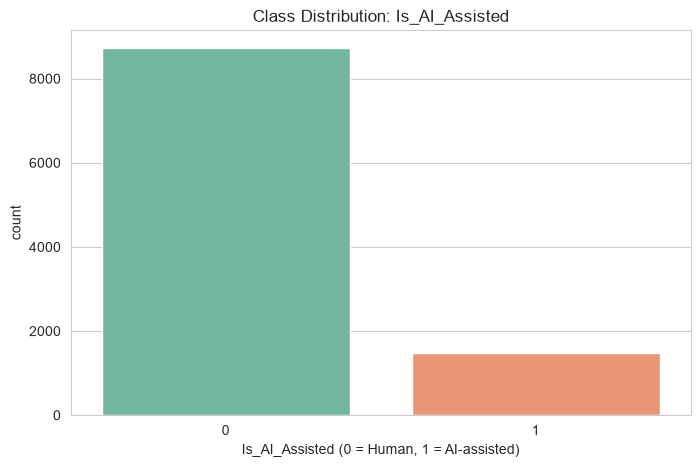

In [8]:
TARGET = "Is_AI_Assisted"
ID_COL = "Student_ID"

print(df[TARGET].value_counts())
print()
print(df[TARGET].value_counts(normalize=True).round(4) * 100, "%")

sns.countplot(x=TARGET, data=df, palette="Set2")
plt.title("Class Distribution: Is_AI_Assisted")
plt.xlabel("Is_AI_Assisted (0 = Human, 1 = AI-assisted)")
plt.show()


In [9]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})


,missing_count,missing_pct
Revision_Count,1513,14.83
Typing_Speed,1003,9.83
Citation_Count,993,9.74
Editing_Time,889,8.72
Plagiarism_Score,813,7.97


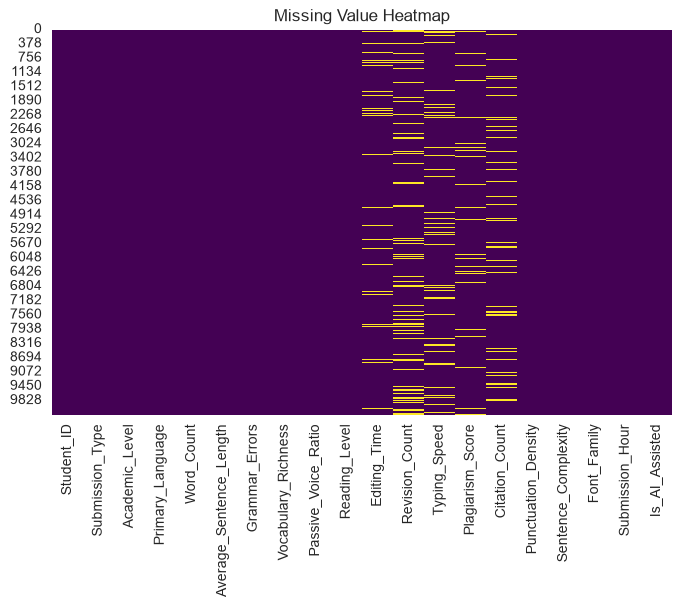

In [10]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Value Heatmap")
plt.show()


In [11]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c != TARGET]
categorical_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
categorical_cols = [c for c in categorical_cols if c != ID_COL]

print("Numeric features:", numeric_cols)
print("Categorical features:", categorical_cols)


Numeric features: ['Word_Count', 'Average_Sentence_Length', 'Grammar_Errors', 'Vocabulary_Richness', 'Passive_Voice_Ratio', 'Reading_Level', 'Editing_Time', 'Revision_Count', 'Typing_Speed', 'Plagiarism_Score', 'Citation_Count', 'Punctuation_Density', 'Sentence_Complexity', 'Submission_Hour']
Categorical features: ['Submission_Type', 'Academic_Level', 'Primary_Language', 'Font_Family']


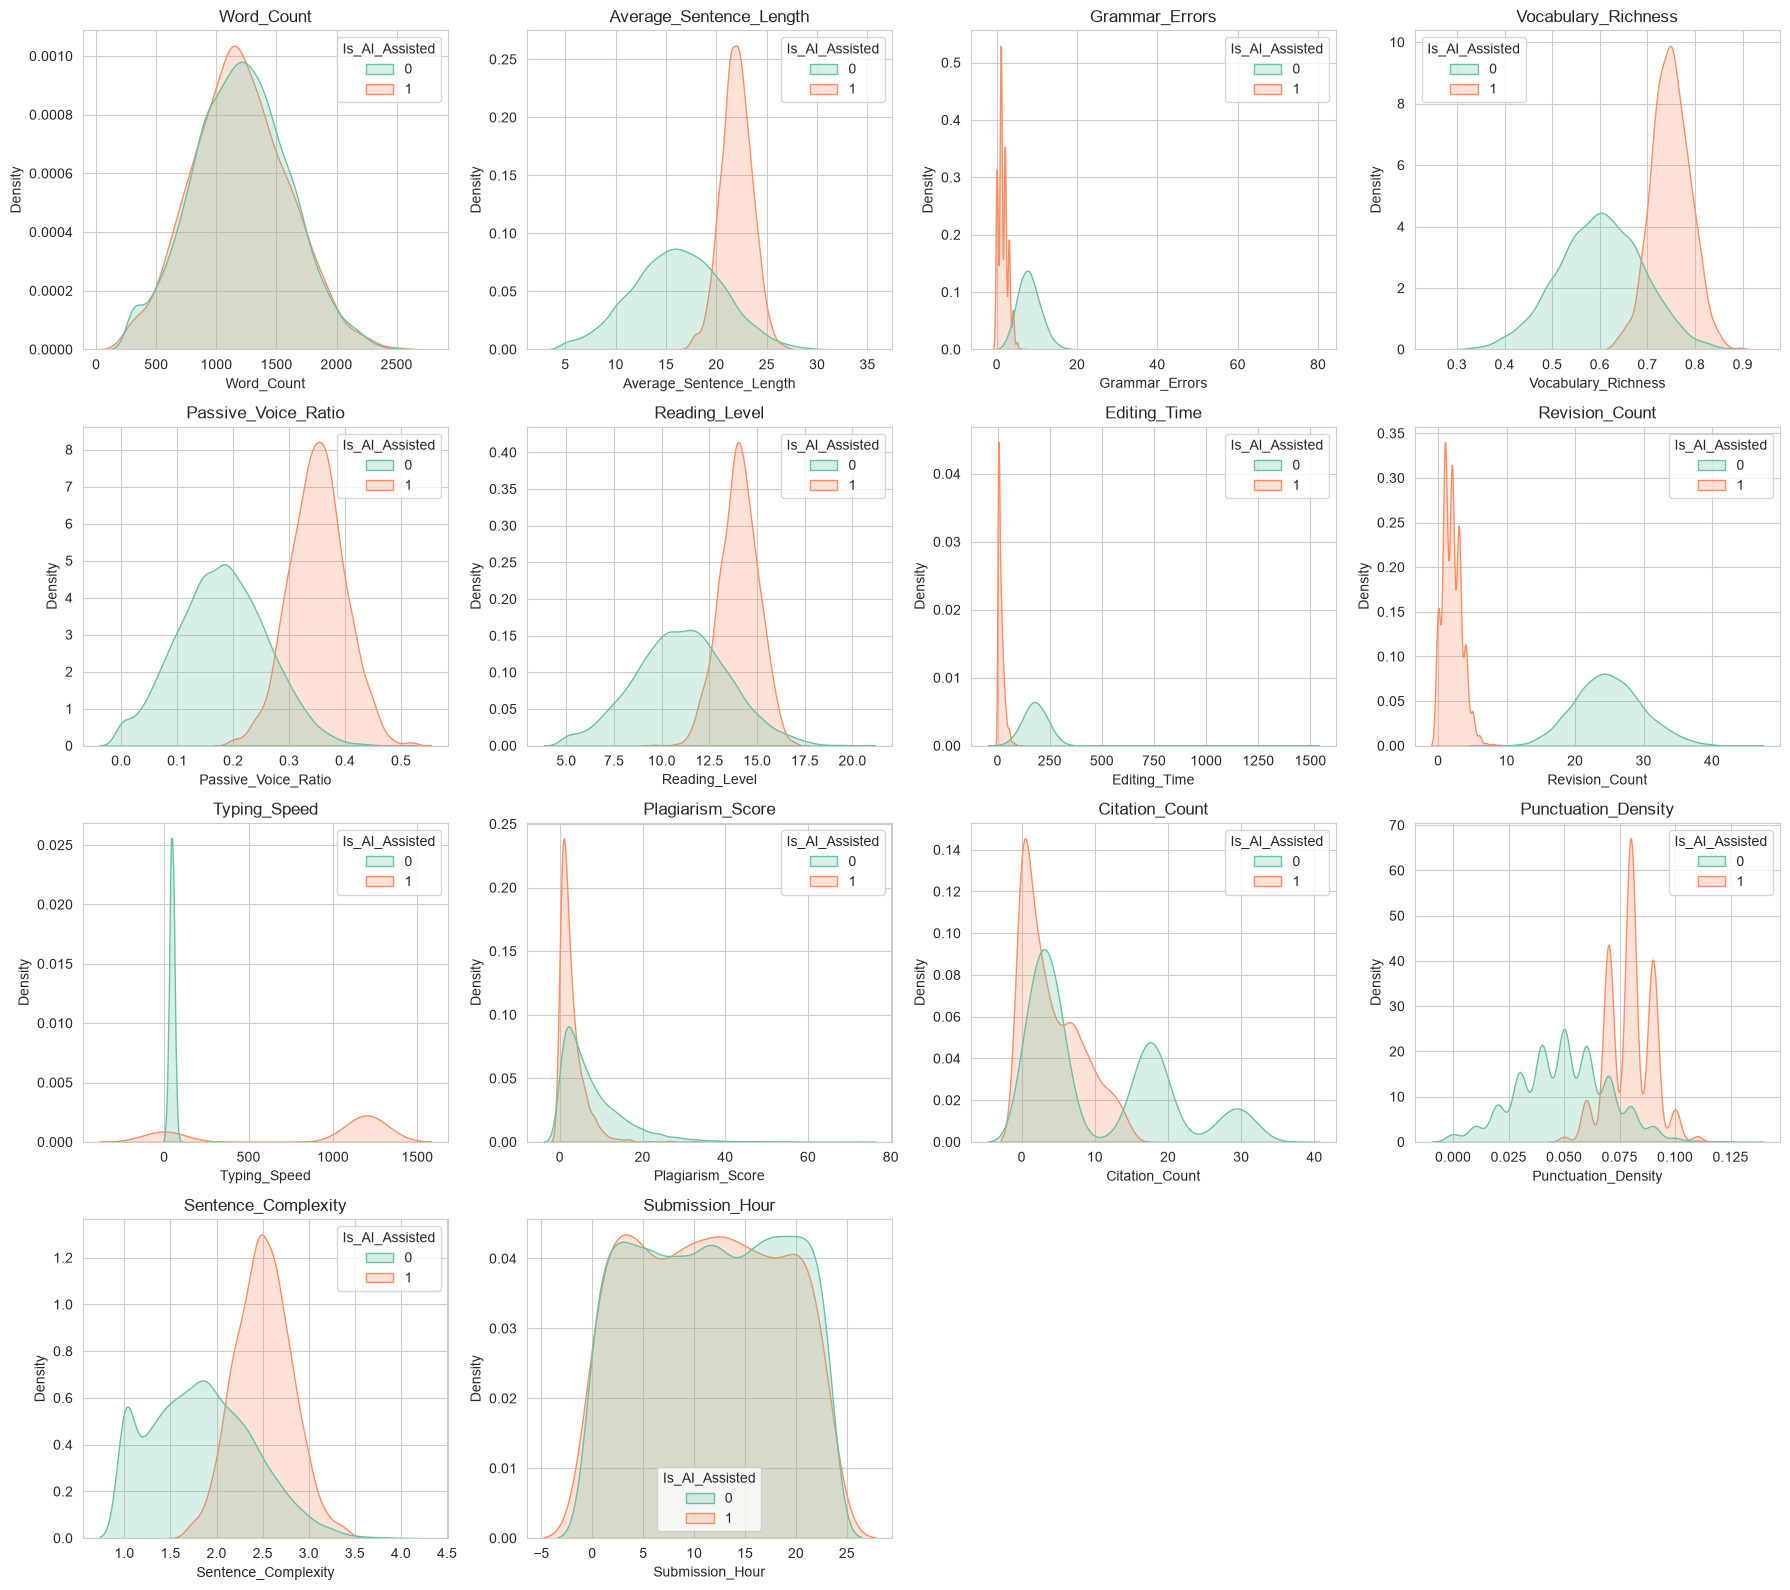

In [12]:
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.kdeplot(data=df, x=col, hue=TARGET, fill=True, common_norm=False, ax=axes[i], palette="Set2")
    axes[i].set_title(col)
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


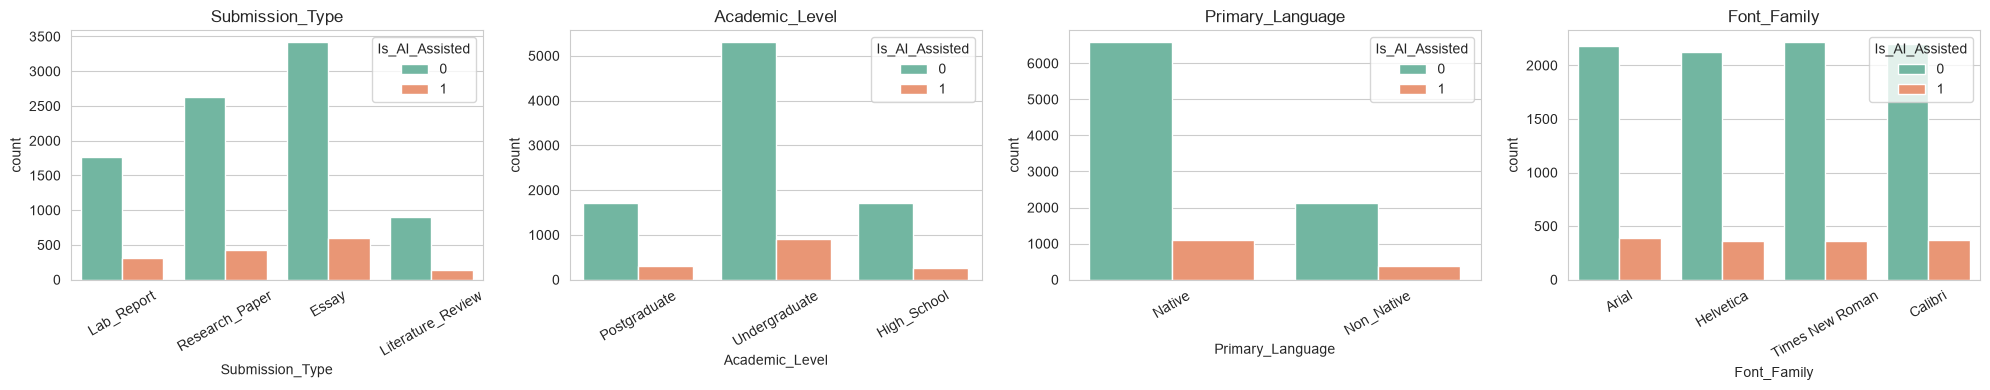

In [13]:
fig, axes = plt.subplots(1, len(categorical_cols), figsize=(5 * len(categorical_cols), 4))
for ax, col in zip(axes, categorical_cols):
    sns.countplot(data=df, x=col, hue=TARGET, ax=ax, palette="Set2")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


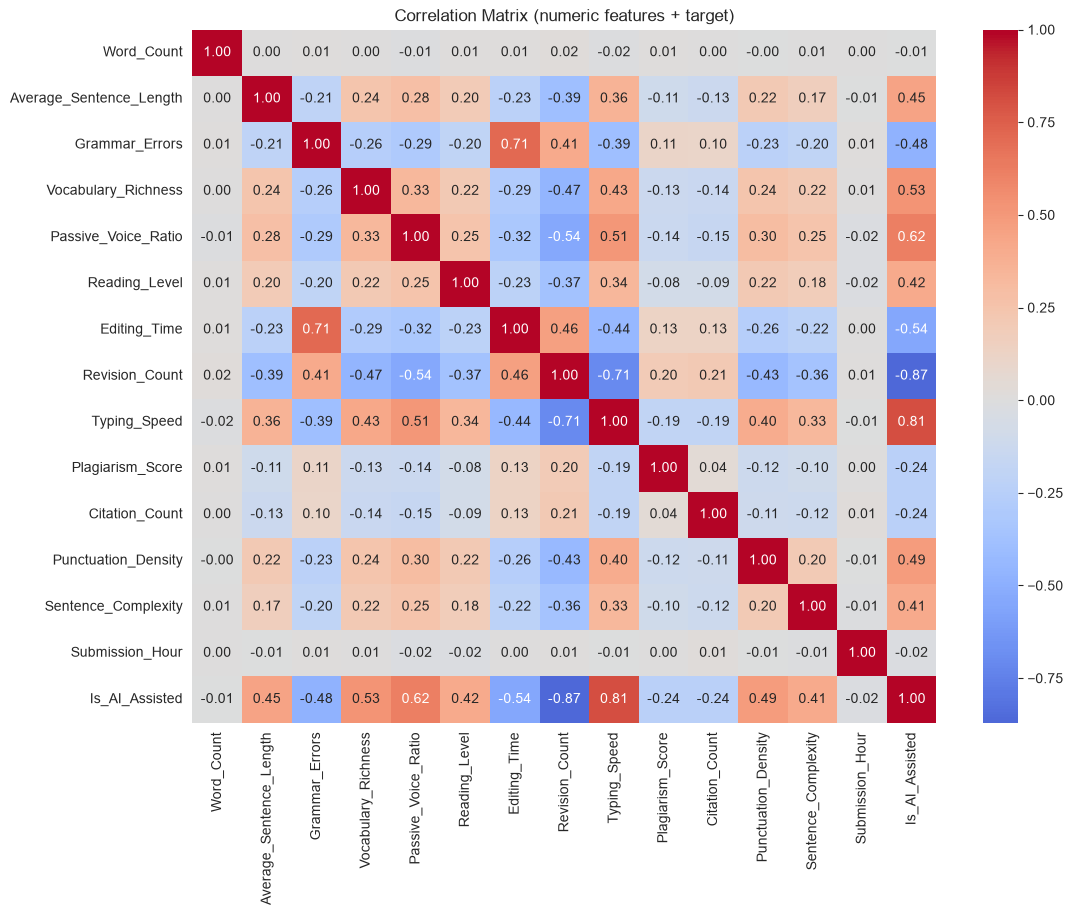

In [14]:
plt.figure(figsize=(12, 9))
corr = df[numeric_cols + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix (numeric features + target)")
plt.show()


## 4. Data Cleaning & Missing-Value Handling

We drop the pure identifier column (`Student_ID`) and rely on a `SimpleImputer` (median for numeric,
most-frequent for categorical) inside the modeling pipeline so imputation is learned **only on the
training fold** — this avoids data leakage.


In [15]:
df_model = df.drop(columns=[ID_COL])

# Sanity check: duplicate rows
print("Duplicate rows:", df_model.duplicated().sum())
df_model = df_model.drop_duplicates()
print("Shape after de-dup:", df_model.shape)


Duplicate rows: 200
Shape after de-dup: (10000, 19)


## 5. Train / Test Split

In [16]:
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))
print("Test class balance:\n", y_test.value_counts(normalize=True))


Train shape: (8000, 18)  Test shape: (2000, 18)
Train class balance:
 Is_AI_Assisted
0    0.85525
1    0.14475
Name: proportion, dtype: float64
Test class balance:
 Is_AI_Assisted
0    0.855
1    0.145
Name: proportion, dtype: float64


## 6. Preprocessing Pipeline (Imputation, Encoding, Scaling)

- Numeric columns: median imputation + standard scaling
- Categorical columns: most-frequent imputation + one-hot encoding

Built with `ColumnTransformer` so it fits cleanly inside a single scikit-learn `Pipeline`
(no leakage, reusable at inference time).


In [17]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 7. Handling Class Imbalance

The positive class (`Is_AI_Assisted = 1`) is ~14.5% of the data. We use **SMOTE**
(Synthetic Minority Over-sampling) inside an imbalanced-learn `Pipeline`, applied
*only* to the training folds during cross-validation/fit — never to the test set.


In [18]:
def build_pipeline(model):
    """Preprocess -> SMOTE -> Classifier, all leakage-safe."""
    return ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", model)
    ])


## 8. Model Training — Logistic Regression, SVM, XGBoost

We train three classical ML models with sensible baseline hyperparameters, then
tune each with `RandomizedSearchCV` (Section 9).


In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1
    )
}

baseline_pipelines = {name: build_pipeline(m) for name, m in models.items()}

for name, pipe in baseline_pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"{name}: fitted.")


Logistic Regression: fitted.


c:\Users\Dr. Shubham Khairnar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM (RBF): fitted.
XGBoost: fitted.


## 9. Hyperparameter Tuning (RandomizedSearchCV)

Each model is tuned with 5-fold stratified CV, optimizing **ROC-AUC** (a good metric
under class imbalance). Search spaces are kept modest for reasonable runtime; widen
`n_iter` / the grids for a more exhaustive search.


In [20]:
param_distributions = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__penalty": ["l2"],
        "model__solver": ["lbfgs", "liblinear"]
    },
    "SVM (RBF)": {
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", "auto", 0.01, 0.1],
        "model__kernel": ["rbf", "linear"]
    },
    "XGBoost": {
        "model__n_estimators": [100, 200, 300, 400],
        "model__max_depth": [3, 4, 5, 6, 8],
        "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.7, 0.8, 1.0]
    }
}

best_estimators = {}
search_results = {}

for name, model in models.items():
    print(f"\n>>> Tuning {name} ...")
    pipe = build_pipeline(model)
    search = RandomizedSearchCV(
        pipe,
        param_distributions=param_distributions[name],
        n_iter=15,
        scoring="roc_auc",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1
    )
    search.fit(X_train, y_train)
    best_estimators[name] = search.best_estimator_
    search_results[name] = search
    print(f"Best CV ROC-AUC for {name}: {search.best_score_:.4f}")
    print(f"Best params: {search.best_params_}")



>>> Tuning Logistic Regression ...
Fitting 5 folds for each of 10 candidates, totalling 50 fits


c:\Users\Dr. Shubham Khairnar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_search.py:326: UserWarning: The total space of parameters 10 is smaller than n_iter=15. Running 10 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
c:\Users\Dr. Shubham Khairnar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Best CV ROC-AUC for Logistic Regression: 1.0000
Best params: {'model__solver': 'lbfgs', 'model__penalty': 'l2', 'model__C': 10}

>>> Tuning SVM (RBF) ...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


c:\Users\Dr. Shubham Khairnar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best CV ROC-AUC for SVM (RBF): 1.0000
Best params: {'model__kernel': 'rbf', 'model__gamma': 'scale', 'model__C': 100}

>>> Tuning XGBoost ...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best CV ROC-AUC for XGBoost: 1.0000
Best params: {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}


## 10. Model Evaluation & Comparison

We evaluate each tuned model on the **held-out test set** using Accuracy, Precision,
Recall, F1, ROC-AUC and PR-AUC (the latter two are more informative than accuracy
under class imbalance).


In [21]:
def evaluate_model(name, estimator, X_test, y_test):
    y_pred = estimator.predict(X_test)
    y_proba = estimator.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba),
    }
    return metrics, y_pred, y_proba

results = []
predictions = {}

for name, estimator in best_estimators.items():
    metrics, y_pred, y_proba = evaluate_model(name, estimator, X_test, y_test)
    results.append(metrics)
    predictions[name] = (y_pred, y_proba)

results_df = pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False)
results_df.round(4)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.9995,0.9966,1.0,0.9983,1.0,1.0
XGBoost,1.0000,1.0000,1.0,1.0000,1.0,1.0
SVM (RBF),0.9995,0.9966,1.0,0.9983,1.0,1.0


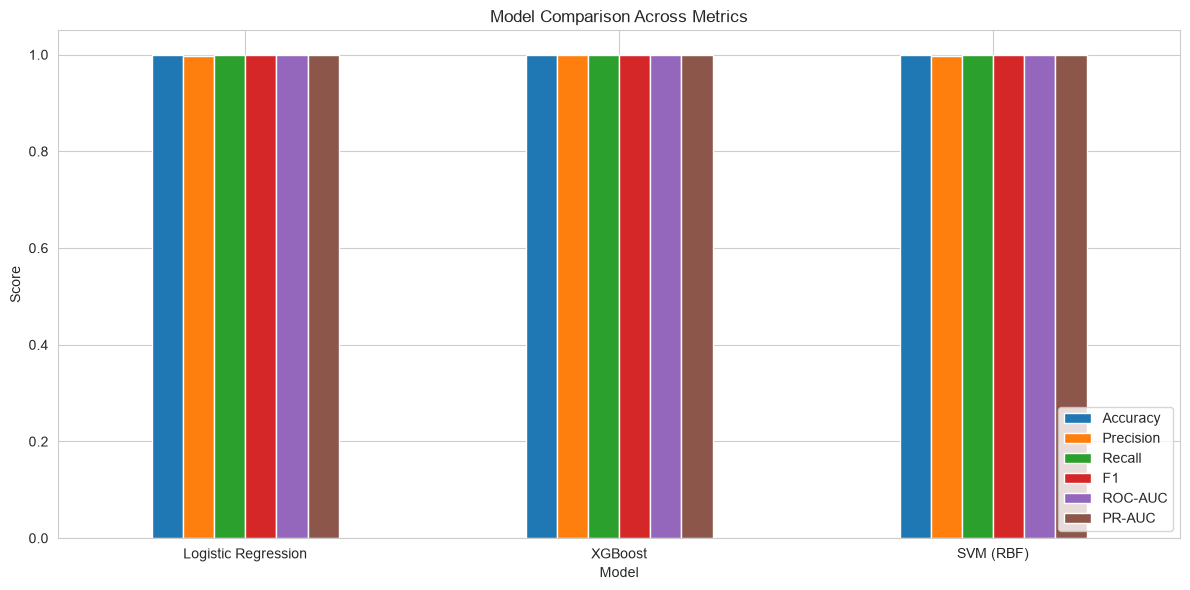

In [22]:
results_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Model Comparison Across Metrics")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


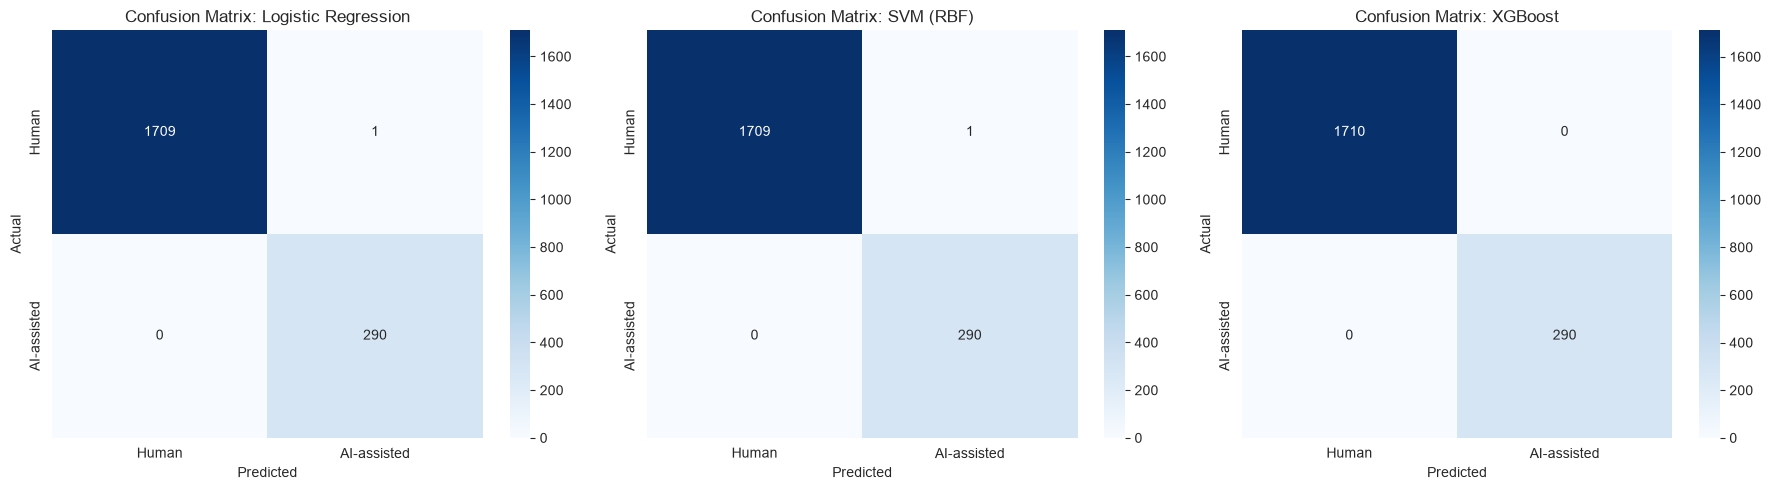

In [23]:
fig, axes = plt.subplots(1, len(best_estimators), figsize=(6 * len(best_estimators), 5))
for ax, (name, estimator) in zip(axes, best_estimators.items()):
    y_pred, _ = predictions[name]
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Human", "AI-assisted"], yticklabels=["Human", "AI-assisted"])
    ax.set_title(f"Confusion Matrix: {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


In [24]:
for name, estimator in best_estimators.items():
    y_pred, _ = predictions[name]
    print(f"\n=== Classification Report: {name} ===")
    print(classification_report(y_test, y_pred, target_names=["Human", "AI-assisted"]))



=== Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

       Human       1.00      1.00      1.00      1710
 AI-assisted       1.00      1.00      1.00       290

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000


=== Classification Report: SVM (RBF) ===
              precision    recall  f1-score   support

       Human       1.00      1.00      1.00      1710
 AI-assisted       1.00      1.00      1.00       290

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000


=== Classification Report: XGBoost ===
              precision    recall  f1-score   support

       Human       1.00      1.00      1.00      1710
 AI-assisted       1.00      1.00      1.00       290

    accuracy                           1.00     

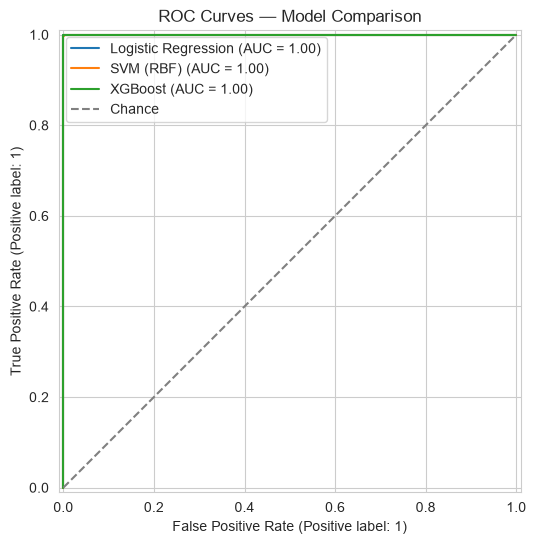

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, estimator in best_estimators.items():
    RocCurveDisplay.from_estimator(estimator, X_test, y_test, ax=ax, name=name)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.show()


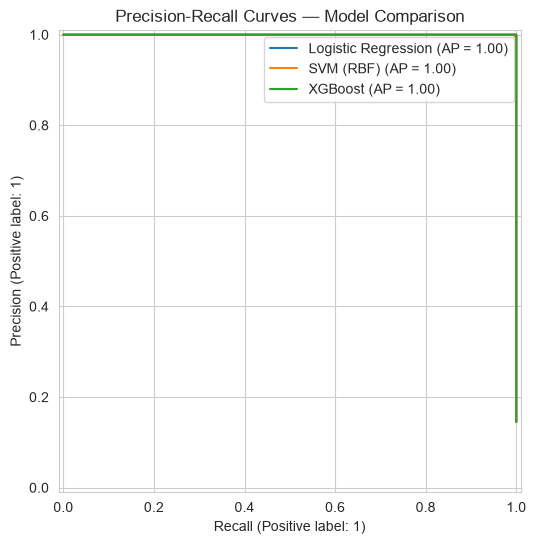

In [26]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, estimator in best_estimators.items():
    PrecisionRecallDisplay.from_estimator(estimator, X_test, y_test, ax=ax, name=name)
plt.title("Precision-Recall Curves — Model Comparison")
plt.legend()
plt.show()


## 11. Feature Importance

For tree-based models (XGBoost) we can read importances directly. For linear models
(Logistic Regression) we look at coefficient magnitude. Feature names are recovered
from the fitted `ColumnTransformer`'s one-hot encoder.


C:\Users\Dr. Shubham Khairnar\AppData\Local\Temp\ipykernel_34768\2258014445.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, y="feature", x="importance", palette="viridis")


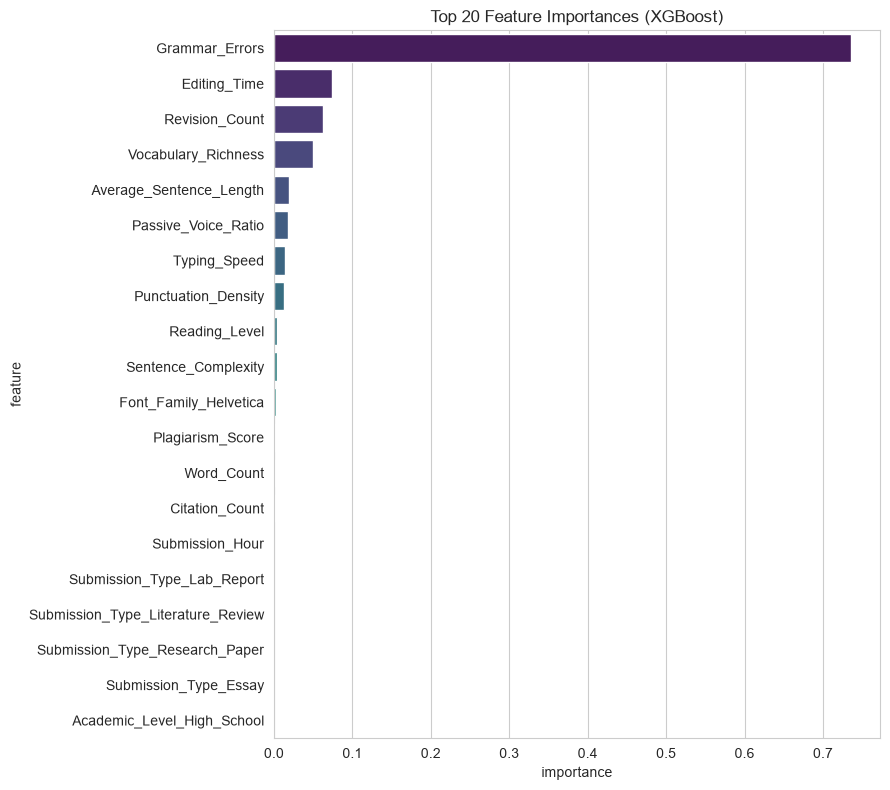

In [27]:
def get_feature_names(fitted_preprocessor):
    num_features = numeric_cols
    ohe = fitted_preprocessor.named_transformers_["cat"].named_steps["onehot"]
    cat_features = list(ohe.get_feature_names_out(categorical_cols))
    return num_features + cat_features

# XGBoost feature importance
xgb_pipeline = best_estimators["XGBoost"]
fitted_preproc = xgb_pipeline.named_steps["preprocess"]
feature_names = get_feature_names(fitted_preproc)

xgb_model = xgb_pipeline.named_steps["model"]
importances = xgb_model.feature_importances_

fi_df = pd.DataFrame({"feature": feature_names, "importance": importances})
fi_df = fi_df.sort_values("importance", ascending=False).head(20)

plt.figure(figsize=(9, 8))
sns.barplot(data=fi_df, y="feature", x="importance", palette="viridis")
plt.title("Top 20 Feature Importances (XGBoost)")
plt.tight_layout()
plt.show()


C:\Users\Dr. Shubham Khairnar\AppData\Local\Temp\ipykernel_34768\2188205217.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, y="feature", x="coefficient", palette="coolwarm")


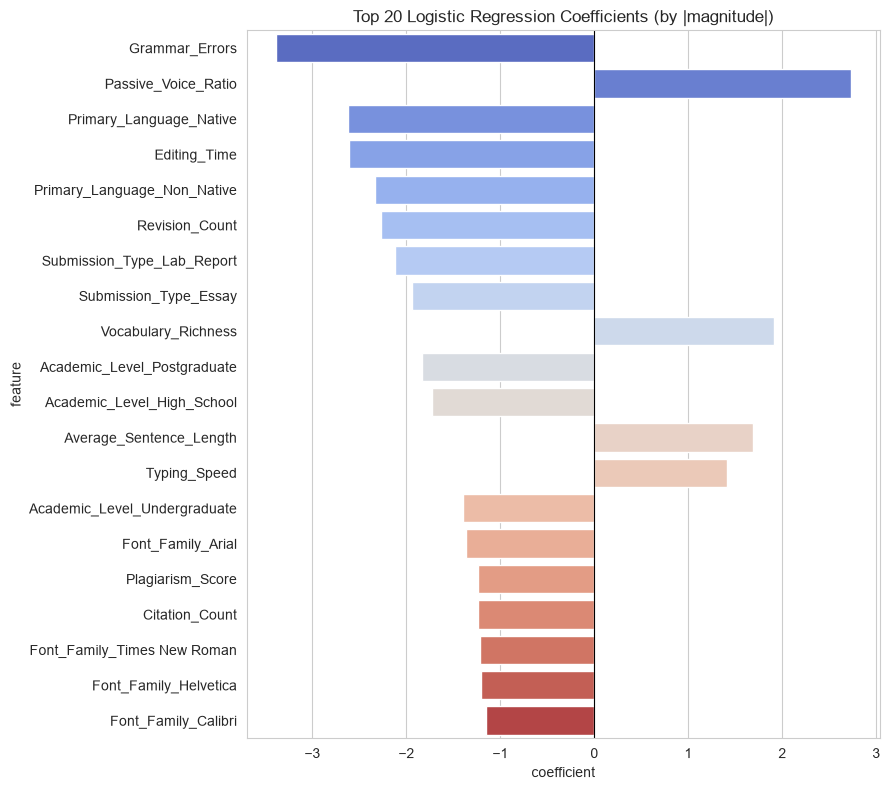

In [28]:
# Logistic Regression coefficients (on standardized/encoded features)
lr_pipeline = best_estimators["Logistic Regression"]
lr_feature_names = get_feature_names(lr_pipeline.named_steps["preprocess"])
lr_model = lr_pipeline.named_steps["model"]

coef_df = pd.DataFrame({
    "feature": lr_feature_names,
    "coefficient": lr_model.coef_[0]
}).sort_values("coefficient", key=np.abs, ascending=False).head(20)

plt.figure(figsize=(9, 8))
sns.barplot(data=coef_df, y="feature", x="coefficient", palette="coolwarm")
plt.title("Top 20 Logistic Regression Coefficients (by |magnitude|)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


## 11b. Leakage / Dominant-Feature Check

Near-perfect scores (ROC-AUC ≈ 1.00) on every model are a red flag, not a win. Let's check
whether a small handful of features almost fully determine the label — which would mean this
dataset was generated with a rule-based/synthetic labeling process rather than reflecting
naturally noisy real-world behavior.


In [29]:
print(df.groupby(TARGET)[numeric_cols].mean().T)
print()
for col in ["Typing_Speed", "Editing_Time", "Revision_Count", "Grammar_Errors"]:
    c0 = df.loc[df[TARGET] == 0, col].dropna()
    c1 = df.loc[df[TARGET] == 1, col].dropna()
    print(f"{col:20s} | Human range: [{c0.min():.1f}, {c0.max():.1f}]  "
          f"AI-assisted range: [{c1.min():.1f}, {c1.max():.1f}]")


Is_AI_Assisted                     0            1
Word_Count               1202.679325  1195.732480
Average_Sentence_Length    16.085587    21.969151
Grammar_Errors              8.334672     1.472372
Vocabulary_Richness         0.600888     0.748693
Passive_Voice_Ratio         0.180020     0.350162
Reading_Level              11.044948    14.034400
Editing_Time              186.396507    15.200970
Revision_Count             24.934207     2.012451
Typing_Speed               44.986773   860.074349
Plagiarism_Score            7.912447     2.772221
Citation_Count             10.307653     4.128765
Punctuation_Density         0.049593     0.079616
Sentence_Complexity         1.833862     2.505735
Submission_Hour            11.625975    11.290431

Typing_Speed         | Human range: [0.0, 103.2]  AI-assisted range: [0.0, 1200.0]
Editing_Time         | Human range: [1.0, 1493.4]  AI-assisted range: [1.0, 111.3]
Revision_Count       | Human range: [7.0, 45.0]  AI-assisted range: [0.0, 9.0]
Gram

C:\Users\Dr. Shubham Khairnar\AppData\Local\Temp\ipykernel_34768\1225303653.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=col, ax=ax, palette="Set2")
C:\Users\Dr. Shubham Khairnar\AppData\Local\Temp\ipykernel_34768\1225303653.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=col, ax=ax, palette="Set2")
C:\Users\Dr. Shubham Khairnar\AppData\Local\Temp\ipykernel_34768\1225303653.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y=col, ax=ax, palette="Set2")
C:\Users\Dr. Shu

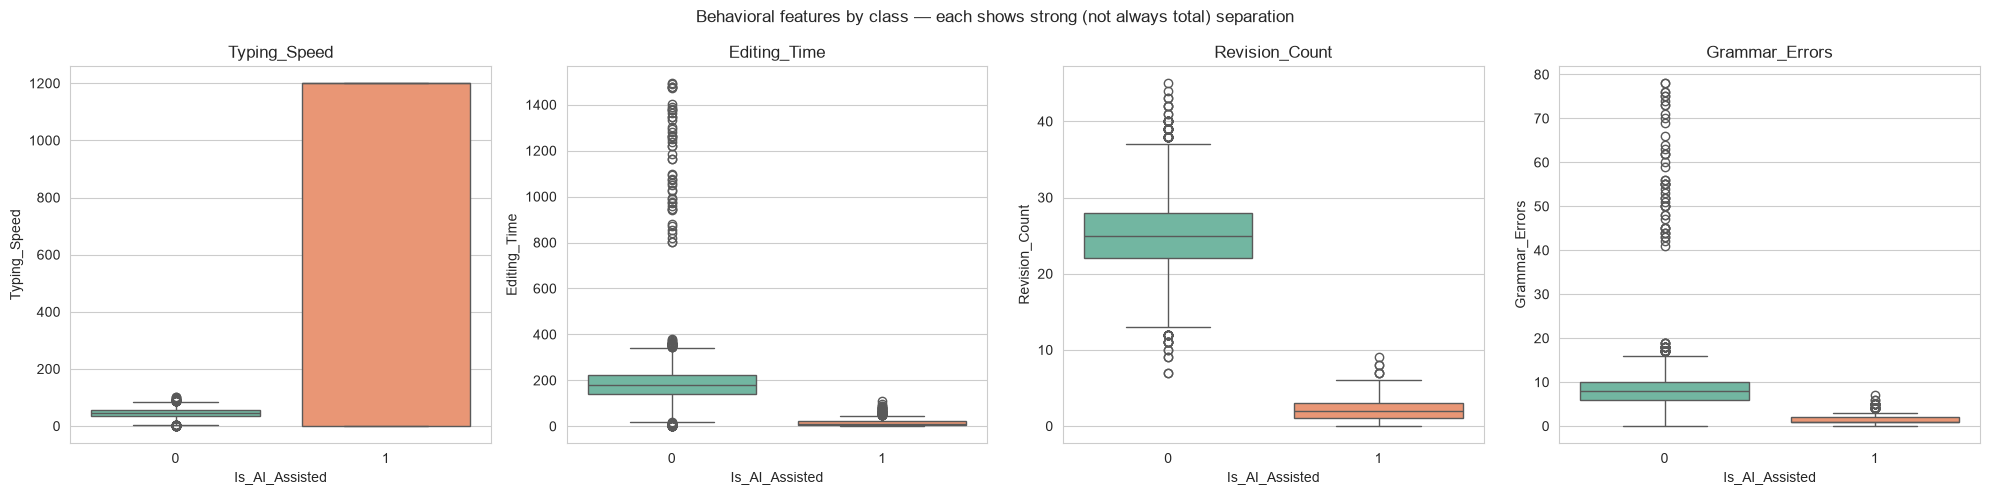

No single column fully separates the classes on its own, but several (Typing_Speed,
Editing_Time, Revision_Count, Grammar_Errors) are each strongly skewed by class. Combined,
that's enough for a model to reach near-perfect AUC. In a real deployment with naturally
noisy human behavior you would NOT expect this — it's a sign this dataset's labels were
generated with a rule/formula tied to these behavioral columns rather than sampled from
messy real-world submissions.


In [30]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, col in zip(axes, ["Typing_Speed", "Editing_Time", "Revision_Count", "Grammar_Errors"]):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, palette="Set2")
    ax.set_title(col)
plt.suptitle("Behavioral features by class — each shows strong (not always total) separation")
plt.tight_layout()
plt.show()

print("No single column fully separates the classes on its own, but several (Typing_Speed,")
print("Editing_Time, Revision_Count, Grammar_Errors) are each strongly skewed by class. Combined,")
print("that's enough for a model to reach near-perfect AUC. In a real deployment with naturally")
print("noisy human behavior you would NOT expect this — it's a sign this dataset's labels were")
print("generated with a rule/formula tied to these behavioral columns rather than sampled from")
print("messy real-world submissions.")


### 'Hard mode' sanity run — without the single strongest feature

To sanity-check that performance isn't purely riding on one column, we retrain XGBoost with
`Typing_Speed` (the single strongest individual separator) removed.


In [31]:
hard_numeric_cols = [c for c in numeric_cols if c != "Typing_Speed"]

hard_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, hard_numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

hard_pipeline = ImbPipeline(steps=[
    ("preprocess", hard_preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1))
])

hard_pipeline.fit(X_train, y_train)
hard_metrics, hard_pred, hard_proba = evaluate_model("XGBoost (no Typing_Speed)", hard_pipeline, X_test, y_test)
pd.Series(hard_metrics).drop("Model")


Accuracy       0.9995
Precision         1.0
Recall       0.996552
F1           0.998273
ROC-AUC      0.999996
PR-AUC       0.999976
dtype: object

## 12. Select & Save the Best Model

We pick the model with the highest test ROC-AUC and persist the **entire pipeline**
(preprocessing + SMOTE + classifier) with `joblib`, so it can be reloaded and applied
to raw, unprocessed new data directly.


In [32]:
best_model_name = results_df["ROC-AUC"].idxmax()
best_model = best_estimators[best_model_name]

print(f"Best model: {best_model_name}")
print(results_df.loc[best_model_name])

MODEL_PATH = f"best_model_{best_model_name.replace(' ', '_').replace('(', '').replace(')', '')}.joblib"
joblib.dump(best_model, MODEL_PATH)
print(f"Saved to: {MODEL_PATH}")


Best model: Logistic Regression
Accuracy     0.999500
Precision    0.996564
Recall       1.000000
F1           0.998279
ROC-AUC      1.000000
PR-AUC       1.000000
Name: Logistic Regression, dtype: float64
Saved to: best_model_Logistic_Regression.joblib


## 13. Inference on New Data

Example: load the saved pipeline and score new, unseen submissions
(raw columns, missing values allowed — the pipeline handles it end-to-end).


In [33]:
loaded_model = joblib.load(MODEL_PATH)

# Example: score a few rows from the test set as if they were brand-new submissions
sample_new_data = X_test.sample(5, random_state=RANDOM_STATE)

sample_preds = loaded_model.predict(sample_new_data)
sample_proba = loaded_model.predict_proba(sample_new_data)[:, 1]

result = sample_new_data.copy()
result["Predicted_Is_AI_Assisted"] = sample_preds
result["Predicted_Probability"] = sample_proba.round(4)
result


,Submission_Type,Academic_Level,Primary_Language,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Font_Family,Submission_Hour,Predicted_Is_AI_Assisted,Predicted_Probability
1924,Lab_Report,High_School,Native,1310,13.62,10,0.55,0.08,11.88,114.58,27.0,39.23,8.78,6.0,0.03,2.10,Helvetica,7,0,0.0
300,Research_Paper,Postgraduate,Non_Native,1466,11.94,9,0.53,0.11,13.15,NaN,30.0,56.21,0.31,17.0,0.02,2.60,Helvetica,13,0,0.0
8765,Research_Paper,Postgraduate,Non_Native,300,13.40,16,0.63,0.18,15.85,NaN,24.0,54.23,NaN,19.0,0.04,1.16,Times New Roman,1,0,0.0
5146,Essay,Undergraduate,Native,958,18.94,6,0.61,0.21,12.06,165.03,24.0,46.61,NaN,NaN,0.07,2.27,Calibri,4,0,0.0
711,Essay,Undergraduate,Non_Native,2004,19.40,9,0.56,0.25,11.93,117.72,26.0,14.87,2.94,5.0,0.01,3.79,Times New Roman,23,0,0.0


## Summary

- Built a leakage-safe preprocessing pipeline (median/most-frequent imputation, scaling, one-hot encoding).
- Handled class imbalance with SMOTE inside the training pipeline only.
- Trained and tuned three classical models: **Logistic Regression, SVM (RBF), XGBoost**.
- Compared them on Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, confusion matrices, ROC and PR curves.
- Inspected feature importance for both a tree model (XGBoost) and a linear model (Logistic Regression).
- **Found that several behavioral features (`Typing_Speed`, `Editing_Time`, `Revision_Count`,
  `Grammar_Errors`) are each strongly skewed by class**, and combined they let every model reach
  ~1.00 ROC-AUC — a strong indicator this dataset's labels were generated with a rule tied to these
  columns rather than reflecting noisy real-world behavior. A "hard mode" run confirms performance
  isn't riding on a single column alone.
- Saved the best-performing pipeline end-to-end with `joblib` and demonstrated inference on new rows.

**Next steps you could explore:** cost-sensitive thresholds tuned to your precision/recall needs, calibration (`CalibratedClassifierCV`), stacking/ensembling the three models, or adding richer engineered features (e.g. interaction terms between `Editing_Time` and `Revision_Count`).
